# Retail Demand Forecasting & Replenishment
**EN:** Daily sales forecasting for Favorita stores (Kaggle Store Sales), then an inventory simulation that turns forecasts into orders.
Heavy logic lives in `src/`; this notebook runs the steps and shows the results.

**TR:** Favorita mağazaları için günlük satış tahmini (Kaggle Store Sales), ardından tahminleri siparişe çeviren bir stok simülasyonu.
Asıl kod `src/` klasöründe; bu notebook adımları çalıştırır ve sonuçları gösterir.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src import data

pd.set_option("display.width", 120)
data.FIG_DIR.mkdir(parents=True, exist_ok=True)

## Step 1 — Data check / Adım 1 — Veri kontrolü
**EN:** Look at size, date range, missing values, zero sales and the sales trend. Then pick a scope that runs fast on a laptop.

**TR:** Boyut, tarih aralığı, eksik değerler, sıfır satışlar ve satış trendine bakıyoruz. Sonra laptopta hızlı çalışacak bir kapsam seçiyoruz.

In [2]:
# Full training file: size, dates, missing values
# Tüm eğitim dosyası: boyut, tarihler, eksik değerler
train = data.load_train()
print("rows:", len(train), "| stores:", train.store_nbr.nunique(), "| families:", train.family.nunique())
print("dates:", train.date.min().date(), "->", train.date.max().date())

# Missing calendar days (stores closed on Dec 25)
# Takvimde eksik günler (25 Aralık mağazalar kapalı)
full = pd.date_range(train.date.min(), train.date.max())
print("missing days:", [d.date() for d in full.difference(train.date.unique())])
print("missing values per column:", train.isna().sum().to_dict())

rows: 3000888 | stores: 54 | families: 33
dates: 2013-01-01 -> 2017-08-15
missing days: [datetime.date(2013, 12, 25), datetime.date(2014, 12, 25), datetime.date(2015, 12, 25), datetime.date(2016, 12, 25)]
missing values per column: {'date': 0, 'store_nbr': 0, 'family': 0, 'sales': 0, 'onpromotion': 0}


In [3]:
# Zero sales: how common, and which families
# Sıfır satışlar: ne kadar yaygın, hangi ailelerde
print("zero-sales share (all):", round((train.sales == 0).mean(), 3))
zero_by_fam = train.groupby("family", observed=True).sales.apply(lambda s: (s == 0).mean())
share_by_fam = train.groupby("family", observed=True).sales.sum() / train.sales.sum()
pd.DataFrame({"sales_share": share_by_fam, "zero_share": zero_by_fam}).sort_values("sales_share", ascending=False).round(3).head(15)

zero-sales share (all): 0.313


,sales_share,zero_share
family,,
GROCERY I,0.320,0.081
BEVERAGES,0.202,0.081
PRODUCE,0.114,0.284
CLEANING,0.091,0.081
DAIRY,0.060,0.081
BREAD/BAKERY,0.039,0.081
POULTRY,0.030,0.081
MEATS,0.029,0.081
PERSONAL CARE,0.023,0.081


In [4]:
# Other files: rows and missing values
# Diğer dosyalar: satır sayısı ve eksik değerler
for name, df in {"oil": pd.read_csv(data.DATA_DIR / "oil.csv"),
                 "holidays": data.load_holidays(),
                 "transactions": data.load_transactions(),
                 "stores": data.load_stores()}.items():
    print(f"{name:13s} rows={len(df):6d} missing={df.isna().sum().sum()}")
print(data.load_holidays().type.value_counts().to_dict())

oil           rows=  1218 missing=43
holidays      rows=   350 missing=0
transactions  rows= 83488 missing=0
stores        rows=    54 missing=0
{'Holiday': 221, 'Event': 56, 'Additional': 51, 'Transfer': 12, 'Bridge': 5, 'Work Day': 5}


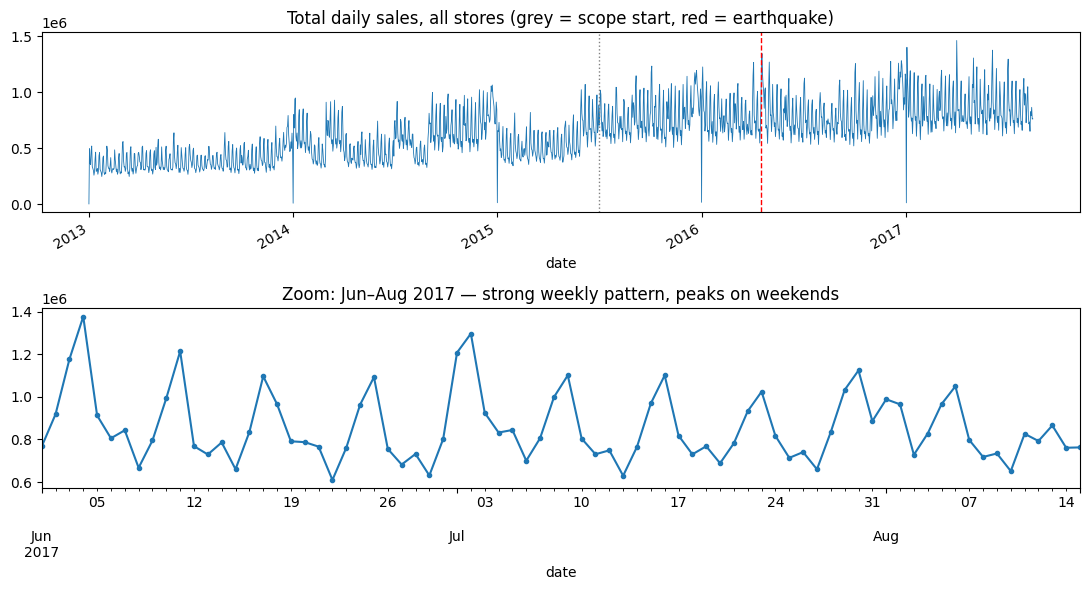

In [5]:
# Total sales over time; red line = 2016-04-16 earthquake
# Zaman içinde toplam satış; kırmızı çizgi = 16.04.2016 depremi
daily = train.groupby("date").sales.sum()
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
daily.plot(ax=ax[0], lw=0.6)
ax[0].axvline(pd.Timestamp("2016-04-16"), color="red", ls="--", lw=1)
ax[0].axvline(pd.Timestamp(data.SCOPE_START), color="grey", ls=":", lw=1)
ax[0].set_title("Total daily sales, all stores (grey = scope start, red = earthquake)")
daily["2017-06-01":].plot(ax=ax[1], marker=".")
ax[1].set_title("Zoom: Jun–Aug 2017 — strong weekly pattern, peaks on weekends")
plt.tight_layout(); plt.savefig(data.FIG_DIR / "01_sales_over_time.png", dpi=110); plt.show()

In [6]:
# Chosen scope: all 54 stores x top-10 families, from 2015-07-01
# Seçilen kapsam: 54 mağaza x ilk 10 aile, 2015-07-01'den itibaren
df = data.load_scope()
n_series = df.groupby(["store_nbr", "family"], observed=True).ngroups
print("rows:", len(df), "| series:", n_series, "| dates:", df.date.min().date(), "->", df.date.max().date())
print("families:", list(df.family.cat.categories))
print("share of total sales covered:", round(df.sales.sum() / train.loc[train.date >= data.SCOPE_START, "sales"].sum(), 3))
print("zero-sales share in scope:", round((df.sales == 0).mean(), 3))

rows: 411250 | series: 540 | dates: 2015-07-01 -> 2017-08-15
families: ['BEVERAGES', 'BREAD/BAKERY', 'CLEANING', 'DAIRY', 'DELI', 'GROCERY I', 'MEATS', 'PERSONAL CARE', 'POULTRY', 'PRODUCE']
share of total sales covered: 0.93
zero-sales share in scope: 0.01


## Step 2 — Baselines / Adım 2 — Baseline modeller
**EN:** Two simple forecasts that any model must beat:
- **Naive:** every future day = the last known day.
- **Seasonal naive:** every future day = the same weekday in the last known week.

We test them on 4 rolling 16-day windows (the same windows used for LightGBM later). Each forecast only sees data up to its cutoff.

**TR:** Her modelin geçmesi gereken iki basit tahmin:
- **Naive:** gelecekteki her gün = bilinen son gün.
- **Seasonal naive:** gelecekteki her gün = bilinen son haftada aynı haftanın günü.

Bunları 4 adet kayan 16 günlük pencerede test ediyoruz (sonra LightGBM için de aynı pencereler). Her tahmin sadece kendi cutoff tarihine kadarki veriyi görür.

In [7]:
from src import baselines, evaluate

# Backtest windows: cutoff = last day the model may see
# Backtest pencereleri: cutoff = modelin görebileceği son gün
folds = evaluate.make_folds()
folds

,fold,cutoff,test_start,test_end
0,1,2017-06-12,2017-06-13,2017-06-28
1,2,2017-06-28,2017-06-29,2017-07-14
2,3,2017-07-14,2017-07-15,2017-07-30
3,4,2017-07-30,2017-07-31,2017-08-15


In [8]:
# Run both baselines on every fold and score them
# Her iki baseline'ı her fold'da çalıştır ve puanla
KEYS = ["date", "store_nbr", "family"]
base_preds, rows = [], []
for f in folds.itertuples():
    actual = df[(df.date >= f.test_start) & (df.date <= f.test_end)][KEYS + ["sales"]]
    for name, fn in {"naive": baselines.naive, "seasonal_naive": baselines.seasonal_naive}.items():
        pred = fn(df[df.date <= f.cutoff], f.cutoff, evaluate.HORIZON)
        m = actual.merge(pred, on=KEYS, how="left").assign(fold=f.fold, model=name)
        base_preds.append(m)
        rows.append({"fold": f.fold, "model": name, **evaluate.metrics(m.sales, m.pred)})
base_preds = pd.concat(base_preds, ignore_index=True)
base_scores = pd.DataFrame(rows)
base_scores.pivot(index="fold", columns="model", values=["MAE", "RMSE", "WAPE"]).round(3)

MAE                     RMSE                  WAPE               
model    naive seasonal_naive     naive seasonal_naive  naive seasonal_naive
fold                                                                        
1      316.016        227.921   716.284        532.965  0.225          0.162
2      444.873        232.726  1039.506        579.011  0.298          0.156
3      383.811        195.402   857.639        482.172  0.259          0.132
4      627.933        282.462  1313.135        628.457  0.438          0.197

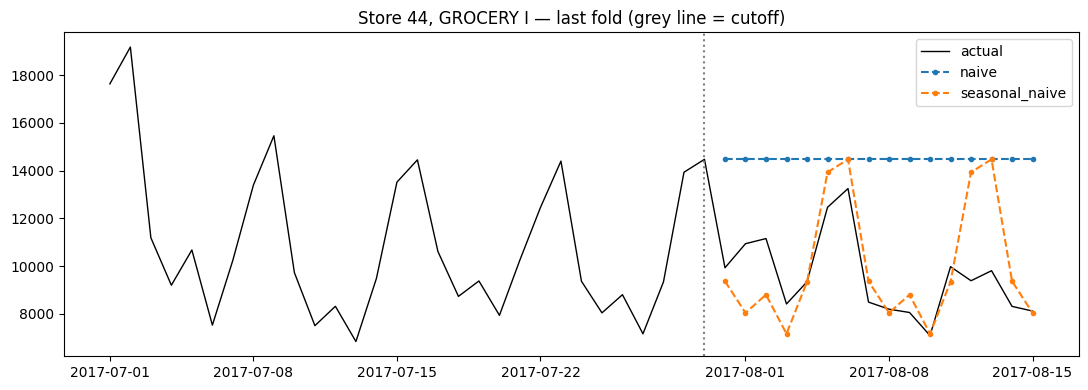

In [9]:
# Example series in the last fold: actual vs. baselines
# Son fold'da örnek bir seri: gerçek satış ve baseline'lar
ex = base_preds[(base_preds.fold == 4) & (base_preds.store_nbr == 44) & (base_preds.family == "GROCERY I")]
hist = df[(df.store_nbr == 44) & (df.family == "GROCERY I") & (df.date >= "2017-07-01")]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hist.date, hist.sales, color="black", lw=1, label="actual")
for name, g in ex.groupby("model"):
    ax.plot(g.date, g.pred, ls="--", marker=".", label=name)
ax.axvline(folds.cutoff.iloc[-1], color="grey", ls=":")
ax.set_title("Store 44, GROCERY I — last fold (grey line = cutoff)"); ax.legend()
plt.tight_layout(); plt.savefig(data.FIG_DIR / "02_baselines_example.png", dpi=110); plt.show()

## Step 3 — LightGBM with features / Adım 3 — Özelliklerle LightGBM
**EN:** One global LightGBM model for all 540 series, trained on `log1p(sales)`.
- **Lags 7/14/28, rolling means 7/28, same-weekday mean of last 4 weeks.**
- **Calendar, payday** (15th and last day of month), **promotions** (known in advance).
- **Holidays:** a transferred holiday counts on its *Transfer* date, not the original date. Bridge and Work Day get their own flags. Regional and local holidays only apply to stores in that state or city.
- **Oil price:** 28-day mean, shifted 16 days, because future oil prices are unknown when we forecast.
- **Earthquake (2016-04-16 → 05-16):** these weeks are removed from training.

**No leakage:** for 16 days ahead, `lag_7` would look into the future. So we forecast **recursively**: predict day 1, use it as history, predict day 2, and so on.

**TR:** 540 serinin hepsi için tek bir global LightGBM modeli, hedef `log1p(satış)`.
- **Lag 7/14/28, rolling ortalama 7/28, son 4 haftada aynı günün ortalaması.**
- **Takvim, maaş günü** (ayın 15'i ve son günü), **promosyon** (önceden bilinir).
- **Tatiller:** taşınan tatil, orijinal tarihte değil *Transfer* tarihinde sayılır. Bridge ve Work Day ayrı bayraklar. Bölgesel ve yerel tatiller sadece o eyalet veya şehirdeki mağazalara uygulanır.
- **Petrol fiyatı:** 28 günlük ortalama, 16 gün kaydırılmış, çünkü tahmin anında gelecek fiyat bilinmez.
- **Deprem (16.04 → 16.05.2016):** bu haftalar eğitimden çıkarıldı.

**Sızıntı yok:** 16 gün ileriyi tahmin ederken `lag_7` geleceğe bakar. Bu yüzden **recursive** tahmin yapıyoruz: 1. günü tahmin et, geçmiş gibi kullan, 2. günü tahmin et, ve böyle devam et.

In [10]:
from src import features, model

# Build all features once (lags are rebuilt inside the recursive forecast)
# Tüm özellikleri bir kez kur (lag'ler recursive tahmin içinde yeniden kurulur)
feat = features.add_lag_features(features.add_exogenous(df))
print(feat.shape, "| features used:", len(features.FEATURES))
print(features.FEATURES)

(411250, 28) | features used: 24
['store_nbr', 'family', 'store_type', 'cluster', 'lag_7', 'lag_14', 'lag_28', 'rmean_7', 'rmean_28', 'dow_mean_4w', 'dayofweek', 'day', 'month', 'dayofyear', 'is_payday', 'days_since_payday', 'onpromotion', 'promo_share_family', 'hol_national', 'hol_local', 'is_bridge', 'is_workday', 'is_event', 'oil_ma28']


In [11]:
# Sanity check: 2017-08-10 holiday was moved to 08-11 (Transfer), payday on 08-15
# Kontrol: 10.08.2017 tatili 11.08'e taşındı (Transfer), maaş günü 15.08
cols = ["date", "hol_national", "is_bridge", "is_workday", "is_payday", "days_since_payday", "oil_ma28"]
feat[(feat.store_nbr == 1) & (feat.family == "GROCERY I") & feat.date.between("2017-08-09", "2017-08-15")][cols]

,date,hol_national,is_bridge,is_workday,is_payday,days_since_payday,oil_ma28
4655,2017-08-09,0,0,0,0,9,45.633571
4656,2017-08-10,0,0,0,0,10,45.759286
4657,2017-08-11,1,0,0,0,11,45.896429
4658,2017-08-12,0,0,0,0,12,46.045357
4659,2017-08-13,0,0,0,0,13,46.177500
4660,2017-08-14,0,0,0,0,14,46.309643
4661,2017-08-15,0,0,0,1,0,46.441786


In [12]:
# Training rows removed: closed days and the earthquake weeks
# Eğitimden çıkarılan satırlar: kapalı günler ve deprem haftaları
print("earthquake rows excluded:", int(feat.quake_period.sum()), "| closed-day rows excluded:", int(feat.is_closed.sum()))

# Train on data up to the last fold's cutoff and forecast 16 days
# Son fold'un cutoff tarihine kadar eğit ve 16 gün tahmin et
last = folds.iloc[-1]
lgb_model = model.train(feat, last.cutoff)
lgb_pred = model.forecast_recursive(lgb_model, feat, last.cutoff, evaluate.HORIZON)

actual = df[(df.date >= last.test_start) & (df.date <= last.test_end)][KEYS + ["sales"]]
m = actual.merge(lgb_pred, on=KEYS)
scores = base_scores[base_scores.fold == last.fold].set_index("model")[["MAE", "RMSE", "WAPE"]]
scores.loc["lightgbm"] = evaluate.metrics(m.sales, m.pred)
scores.round(3)

earthquake rows excluded: 16430 | closed-day rows excluded: 1060


,MAE,RMSE,WAPE
model,,,
naive,627.933,1313.135,0.438
seasonal_naive,282.462,628.457,0.197
lightgbm,192.544,411.356,0.134


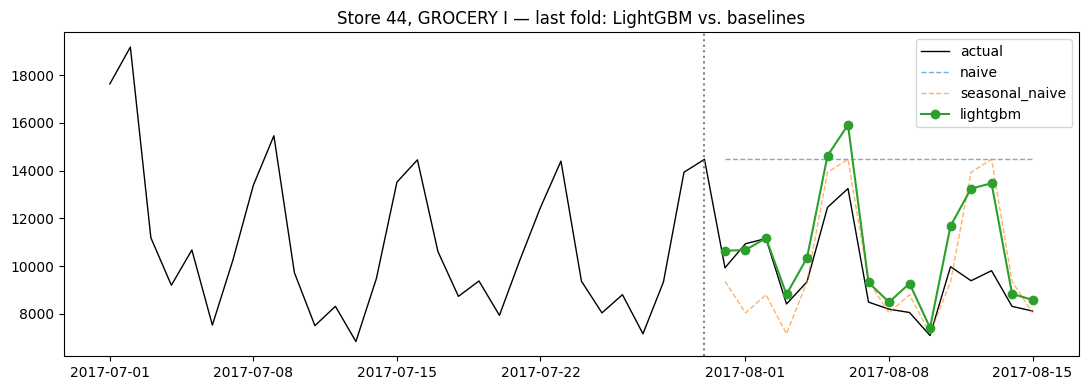

In [13]:
# Same example series as in Step 2, now with LightGBM
# Adım 2'deki aynı örnek seri, şimdi LightGBM ile
ex_l = lgb_pred[(lgb_pred.store_nbr == 44) & (lgb_pred.family == "GROCERY I")]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hist.date, hist.sales, color="black", lw=1, label="actual")
for name, g in ex.groupby("model"):
    ax.plot(g.date, g.pred, ls="--", lw=1, alpha=0.6, label=name)
ax.plot(ex_l.date, ex_l.pred, marker="o", color="tab:green", label="lightgbm")
ax.axvline(last.cutoff, color="grey", ls=":")
ax.set_title("Store 44, GROCERY I — last fold: LightGBM vs. baselines"); ax.legend()
plt.tight_layout(); plt.savefig(data.FIG_DIR / "03_lightgbm_example.png", dpi=110); plt.show()